In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Import Supervised Learning Algorithms
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier, BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier


In [4]:
df = pd.read_csv('income_evaluation.csv')
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
df.columns = df.columns.str.strip()

In [6]:
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.5 MB
None

Missing Values:
 age               0
workclass         0
fnlwgt            0
education         0
education-num     0
ma

/var/folders/70/s6bttn7d6_qdr8b28nj_vt640000gn/T/ipykernel_55222/2907422822.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='income', data=df, palette='Set2')


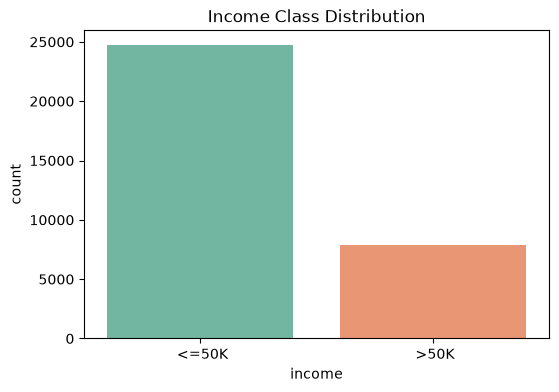

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df, palette='Set2')
plt.title('Income Class Distribution')
plt.show()

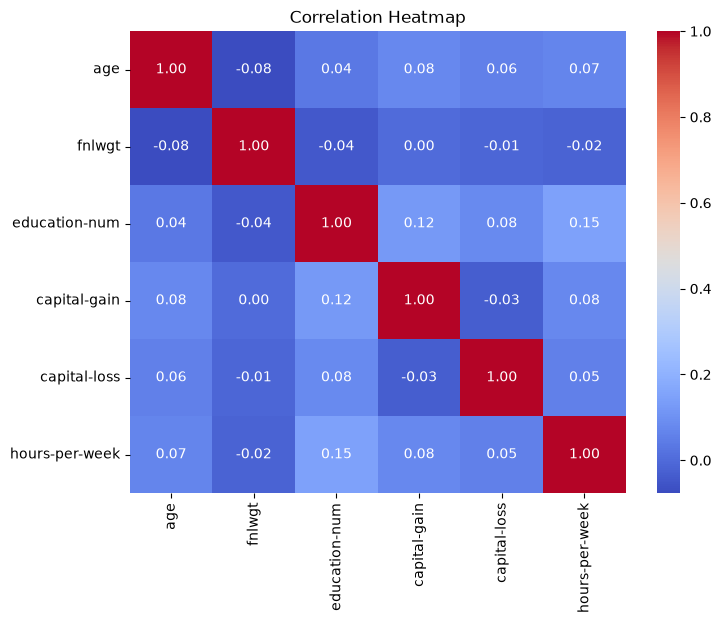

In [8]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [9]:
num_cols = df.select_dtypes(include=[np.number]).columns
print("Skewness of numerical features:\n", df[num_cols].skew())

Skewness of numerical features:
 age                0.558743
fnlwgt             1.446980
education-num     -0.311676
capital-gain      11.953848
capital-loss       4.594629
hours-per-week     0.227643
dtype: float64


In [10]:
skewed_features = ['capital-gain', 'capital-loss', 'fnlwgt']
for col in skewed_features:
    df[col] = np.log1p(df[col])

In [11]:
for col in ['age', 'hours-per-week']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = np.clip(df[col], lower_bound, upper_bound)

In [12]:
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))

/var/folders/70/s6bttn7d6_qdr8b28nj_vt640000gn/T/ipykernel_55222/3790181639.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [13]:
X = df.drop('income', axis=1)
y = df['income']

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Ridge Classifier": RidgeClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "K-Neighbors": KNeighborsClassifier(),
    "Bagging": BaggingClassifier(random_state=42),
    "Voting": VotingClassifier(
        estimators=[
            ('lr', LogisticRegression(max_iter=1000)), 
            ('rf', RandomForestClassifier(random_state=42)),
            ('gb', GradientBoostingClassifier(random_state=42))
        ], 
        voting='hard'
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted')
    rec = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)

In [17]:
print("\n==================================================")
print("     MODEL PERFORMANCE COMPARISON TABLE (INCOME)    ")
print("==================================================")
display(results_df)


     MODEL PERFORMANCE COMPARISON TABLE (INCOME)    


,Model,Accuracy,Precision,Recall,F1 Score
4,Gradient Boosting,0.868724,0.863712,0.868724,0.862620
8,Voting,0.865653,0.860610,0.865653,0.858113
3,Random Forest,0.861508,0.856477,0.861508,0.857563
5,AdaBoost,0.854138,0.847847,0.854138,0.844538
7,Bagging,0.846614,0.839634,0.846614,0.840782
6,K-Neighbors,0.827269,0.825488,0.827269,0.826323
0,Logistic Regression,0.821588,0.809375,0.821588,0.807783
1,Ridge Classifier,0.816521,0.804618,0.816521,0.794616
2,Decision Tree,0.809765,0.814077,0.809765,0.811714


In [18]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print(f"\n Best Performing Model: {best_model_name}")


 Best Performing Model: Gradient Boosting


In [19]:
joblib.dump((best_model, scaler), 'income_model.pkl')
print("Model and scaler successfully saved as 'income_model.pkl'")

Model and scaler successfully saved as 'income_model.pkl'
